# Hotel Booking Data Analysis

**Course:** Data Processing with Python (HAMK)

**Group members:**
1. Anup Kandel
2. Sandesh Bishokarma
3. Sushant Koirala
4. Tanka Raj Aryal

**This notebook:** the part written by Sandesh Bishokarma.

## Relationships and grouped analysis

Complete at least three grouped or two-variable analyses. Together they must include:
- one categorical-versus-categorical analysis using a crosstab;
- one categorical-versus-numerical analysis using `groupby()` and aggregation; and
- one numerical-versus-numerical or time-based analysis.

For crosstabs, show both counts and clearly labelled percentages. State what the percentage denominator is.

**Responsible:** Sandesh Bishokarma (RQ1 crosstab and RQ2 groupby).

In [1]:
# SETUP: makes this file run on its own.
# It repeats Tanka's load + cleaning and Sushant's new columns.
# Anup deletes this cell when he merges everything into the shared notebook.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.2f}".format)

# Chart settings from the lesson notebooks
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# File paths. This file is in notebooks/work/, so the data is two folders up.
# (In the shared notebook Anup changes '../../' to '../'.)
DATA_FILE = "../../data/hotel_bookings_final_project.csv"
CLEAN_FILE = "../../outputs/hotel_bookings_cleaned.csv"
SUMMARY_FILE = "../../outputs/hotel_booking_summary.csv"

hotel_raw = pd.read_csv(DATA_FILE)

hotel = hotel_raw.copy()   # cleaned copy, 'hotel_raw' stays untouched
rows_before = len(hotel)

# Missing country -> "Unknown" (country is not used in our questions)
hotel["country"] = hotel["country"].fillna("Unknown")

# Remove bookings with no guests at all (placeholder records)
hotel = hotel[(hotel["adults"] + hotel["children"] + hotel["babies"]) > 0].copy()

# Duplicates, long lead times and 0 EUR / high rates are kept (see cleaning log)

hotel["arrival_date"] = pd.to_datetime(
    hotel["arrival_date_year"].astype(str) + "-" + hotel["arrival_date_month"] + "-"
    + hotel["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d", errors="coerce")
hotel["total_nights"] = hotel["stays_in_weekend_nights"] + hotel["stays_in_week_nights"]
hotel["total_guests"] = hotel["adults"] + hotel["children"] + hotel["babies"]
hotel["estimated_booking_value"] = hotel["average_daily_rate"] * hotel["total_nights"]

# Optional extra variables that may help our questions
hotel["cancel_status"] = hotel["is_canceled"].map({0: "Not cancelled", 1: "Cancelled"})
hotel["arrival_month_num"] = hotel["arrival_date"].dt.month

# More helper columns, in the style of the lesson notebooks
hotel["booked_far_ahead"] = hotel["lead_time"] > 180          # True / False column
hotel["lead_time_band"] = pd.cut(
    hotel["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, float("inf")],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"],
)

print("Bookings after cleaning:", len(hotel))

Bookings after cleaning: 997


### RQ1: Do cancellation rates differ between the hotels? (Sandesh Bishokarma)

In [2]:
# Categorical x categorical: hotel x cancellation
counts = pd.crosstab(hotel["hotel"], hotel["cancel_status"], margins=True, margins_name="Total")
row_pct = (pd.crosstab(hotel["hotel"], hotel["cancel_status"], normalize="index") * 100).round(1)
print("Counts:")
display(counts)
print("Row percentages (denominator = all bookings for that hotel):")
display(row_pct)

Counts:


cancel_status,Cancelled,Not cancelled,Total
hotel,,,
City Hotel,279,360,639
Resort Hotel,87,271,358
Total,366,631,997


Row percentages (denominator = all bookings for that hotel):


cancel_status,Cancelled,Not cancelled
hotel,,
City Hotel,43.70,56.30
Resort Hotel,24.30,75.70


**Denominator:** each percentage is out of all bookings *for that hotel*.
City Hotel bookings were cancelled in **43.7 %** of cases (279 of 639), compared with **24.3 %** (87 of 358) at the Resort Hotel, a gap of about 19 percentage points.

In [3]:
# Second crosstab: deposit type x cancellation
deposit_counts = pd.crosstab(hotel["deposit_type"], hotel["cancel_status"], margins=True, margins_name="Total")
deposit_pct = (pd.crosstab(hotel["deposit_type"], hotel["cancel_status"], normalize="index") * 100).round(1)
print("Counts:")
display(deposit_counts)
print("Row percentages (denominator = all bookings with that deposit type):")
display(deposit_pct)

Counts:


cancel_status,Cancelled,Not cancelled,Total
deposit_type,,,
No Deposit,250,628,878
Non Refund,116,0,116
Refundable,0,3,3
Total,366,631,997


Row percentages (denominator = all bookings with that deposit type):


cancel_status,Cancelled,Not cancelled
deposit_type,,
No Deposit,28.50,71.50
Non Refund,100.00,0.00
Refundable,0.00,100.00


All 116 *Non Refund* bookings were cancelled, against 28.5 % of *No Deposit* bookings. This is striking but should be interpreted **with caution**: it is unusual for customers to cancel bookings they cannot get refunded, so the pattern may reflect how the source data recorded these bookings. We report it but draw no causal conclusion.

### RQ2: Is lead time associated with cancellation? (Sandesh Bishokarma)

In [4]:
lead_summary = (
    hotel.groupby("cancel_status", observed=True)
    .agg(
        bookings=("lead_time", "count"),
        average_lead_time=("lead_time", "mean"),
        median_lead_time=("lead_time", "median"),
        std_lead_time=("lead_time", "std"),
    )
    .sort_values("median_lead_time")
    .round(2)
)
lead_summary

,bookings,average_lead_time,median_lead_time,std_lead_time
cancel_status,,,,
Not cancelled,631,83.76,48.00,94.01
Cancelled,366,142.49,117.00,116.21


In [5]:
# Cancellation rate in each lead-time band (the pd.cut column made in Transformations)
band_summary = (
    hotel.groupby("lead_time_band", observed=True)
    .agg(
        bookings=("is_canceled", "count"),
        cancelled=("is_canceled", "sum"),
        cancel_rate_pct=("is_canceled", "mean"),
    )
)
band_summary["cancel_rate_pct"] = (band_summary["cancel_rate_pct"] * 100).round(1)
band_summary

,bookings,cancelled,cancel_rate_pct
lead_time_band,,,
0-7,143,20,14.00
8-30,170,45,26.50
31-90,252,86,34.10
91-180,220,94,42.70
181-365,184,103,56.00
366+,28,18,64.30


In [6]:
# Filter and sort: the cancelled bookings that were made furthest ahead
far_ahead_cancelled = (
    hotel.loc[
        hotel["booked_far_ahead"] & (hotel["is_canceled"] == 1),
        ["hotel", "lead_time", "arrival_date", "deposit_type", "market_segment"],
    ]
    .sort_values("lead_time", ascending=False)
)
print("Matching records:", len(far_ahead_cancelled))
far_ahead_cancelled.head()

Matching records: 121


,hotel,lead_time,arrival_date,deposit_type,market_segment
509,City Hotel,538,2016-12-29,Non Refund,Groups
380,City Hotel,531,2016-12-22,Non Refund,Groups
59,City Hotel,517,2016-12-08,Non Refund,Groups
506,City Hotel,496,2016-11-17,Non Refund,Groups
454,City Hotel,489,2016-11-10,Non Refund,Groups


Cancelled bookings were made much earlier: median lead time **117 days** versus **48 days** for bookings that were kept.
The cancellation rate rises steadily with lead time, from **14.0 %** for bookings made within a week of arrival to **64.3 %** for bookings made more than a year ahead (n = 28, so this last band is small).

## Final visualizations

At least four finished visualizations (Matplotlib or Pandas plotting): one categorical comparison; one numerical distribution;
one relationship or grouped comparison; one time-based or multi-group figure.

Each needs a descriptive title, clear axis labels, a legend when needed, readable labels, sensible formatting, and the sample size (n).
After each, write a short **What can we observe?** paragraph without unsupported causal claims.

**Responsible:** Sandesh Bishokarma (Figure 1 and Figure 3).

### Figure 1: categorical comparison (Sandesh Bishokarma)

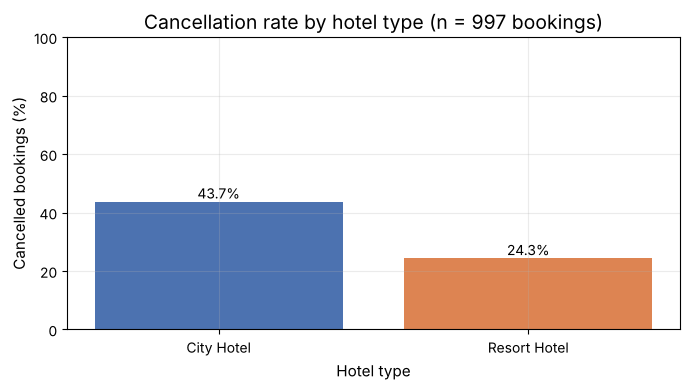

In [7]:
# Figure 1: cancellation rate by hotel
rate = hotel.groupby("hotel")["is_canceled"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(rate.index, rate["mean"] * 100, color=["#4C72B0", "#DD8452"])
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in rate["mean"] * 100])
ax.set_title(f"Cancellation rate by hotel type (n = {rate['count'].sum()} bookings)")
ax.set_xlabel("Hotel type")
ax.set_ylabel("Cancelled bookings (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

**What can we observe?** City Hotel bookings were cancelled more often: 43.7 % of its 639 bookings, compared with 24.3 % of the Resort Hotel's 358. This chart does not tell us *why*; the two hotels also differ in customers, booking channels and lead times.

### Figure 3: grouped comparison (Sandesh Bishokarma)

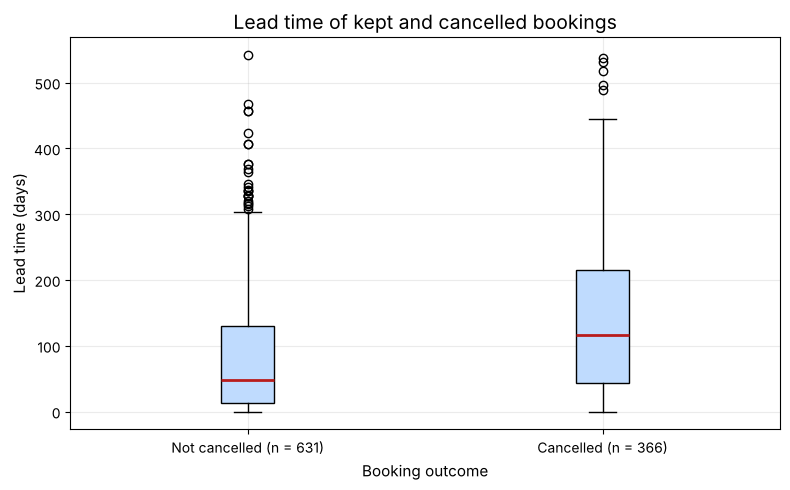

In [8]:
# Figure 3: grouped comparison - box plot of lead time by cancellation status
groups = ["Not cancelled", "Cancelled"]
lead_by_group = [hotel.loc[hotel["cancel_status"] == g, "lead_time"] for g in groups]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    lead_by_group,
    tick_labels=[f"{g} (n = {len(d)})" for g, d in zip(groups, lead_by_group)],
    patch_artist=True,
    boxprops={"facecolor": "#bfdbfe"},
    medianprops={"color": "#b91c1c", "linewidth": 2},
)
ax.set_title("Lead time of kept and cancelled bookings")
ax.set_xlabel("Booking outcome")
ax.set_ylabel("Lead time (days)")
fig.tight_layout()
plt.show()

**What can we observe?** Cancelled bookings were typically made much further in advance: their median lead time is 117 days compared with 48 days for kept bookings, and the whole box sits higher. Lead time is therefore **associated** with cancellation in this sample; we cannot say that booking early *causes* a cancellation.

## Conclusions, limitations, and recommendation

- answers to the three research questions;
- three to five evidence-based findings;
- at least two limitations or cautions;
- one recommendation for the hotel-management audience; and
- one useful next question that cannot be answered with the supplied variables.

**Responsible:** Whole group, led by Sandesh Bishokarma.

**Answers to the research questions**
1. **RQ1:** Yes. City Hotel bookings were cancelled much more often (43.7 %) than Resort Hotel bookings (24.3 %).
2. **RQ2:** Yes, lead time is clearly associated with cancellation. Cancelled bookings had a median lead time of 117 days vs 48 days for kept bookings, and the cancellation rate rises from 14.0 % (≤ 7 days ahead) to 64.3 % (more than a year ahead).
3. **RQ3:** Over the whole sample the City Hotel is busier in every month, and January and November are the quietest months. The apparent July–August peak is mostly caused by uneven year coverage; in the complete year 2016 the busiest months were May and October.

**Key findings**
- More than a third of all bookings (36.7 %) were cancelled.
- The City Hotel has a higher cancellation rate *and* a higher median daily rate (100 € vs 77 €) than the Resort Hotel.
- Resort guests stay longer (4.2 vs 3.0 nights on average), so median booking values are almost the same at both hotels (about 270 €).
- All 116 *Non Refund* bookings in the sample were cancelled, an unexpected pattern that needs checking at the source.

**Limitations / cautions**
- The data is a 1,000-booking sample from only two hotels, 2015–2017, so results may not apply to other hotels or years.
- The years are incomplete (2015: Jul–Dec, 2017: Jan–Aug), which inflates July–August in the all-years totals.
- The patterns are associations, not causes; for example, the City Hotel's higher cancellation rate may be explained by other differences such as lead time or booking channel.
- Some decisions (keeping duplicates, keeping 0 € rates) are judgement calls; removing the duplicates would lower the overall cancellation rate only slightly.

**Recommendation for hotel management:** treat bookings made far in advance, especially at the City Hotel, as a higher cancellation risk, for example by sending a reminder/confirmation message a few weeks before arrival, and plan seasonal capacity from complete years of data.

**A next question these variables can't answer:** *why* guests cancel (price found elsewhere, plans changed, group got smaller). The data has no cancellation reason or cancellation date.